# exp2_replication_no_res — replication under corrected training

Bridges the manuscript's original Study 1 conditions to the **corrected
training regime**, without the resource-observation fix of `exp1`. Same 2×2
design as the paper (`see_emotions` × `alpha`), with `see_resource=False`.

**Since 14/10/2026 exp2 is the resource moderator of Axis 1:** own meals stay
visible (`see_own_meals=True`), so only the resource observation differs from
`exp1`. It no longer reproduces the paper's observation exactly, and the
paragraph below describes that earlier design.

**Why this run exists, and why it is not redundant with exp1.** `exp1`
answers "what happens once agents also see `r_t`?" — but that re-run changes
*two* things at once relative to the manuscript: the observation (`r_t`
added) and the training procedure (persistent replay buffer across episodes,
epsilon decaying per episode instead of per step, 20 seeds instead of 4 — see
`README.md` §"Correspondance reviews → changements"). If a manuscript claim
comes out different in `exp1`, that difference could be caused by either
change. `exp2` isolates the training fix alone, by reproducing the paper's
exact observation conditions under the corrected procedure. Reading `exp1`
and `exp2` side by side then isolates what the resource-observation fix
specifically contributes: `exp2` is the counterfactual "same information as
the paper, just trained properly".

**Design**

| cell | condition | `see_emotions` | `alpha` |
|---|---|---|---|
| A | `A_nores_blind_non_empathic` | False | 0.0 |
| B | `B_nores_blind_reward_empathic` | False | 0.5 |
| C | `C_nores_sees_ignores` | True | 0.0 |
| D | `D_nores_full_empathy` | True | 0.5 |

In every cell, the *reward* still integrates the empathic term
`r_i = (1 − α)·personal_i + α·empathic_i` exactly as in the paper —
`see_emotions` only gates what the agent can *observe*, never what its reward
is computed from (`env_gt_ais.py`, `SocialRewardCalculator.calculate_rewards`).
Cell B is the condition asked about earlier in this project: emotions hidden
from the observation, but still weighted into the reward at α = 0.5.

**Two metrics** (used identically across every notebook in this folder)
- **Depletion step** (`total_steps`) — how long the shared pool survives
  before `resource <= 0` ends the episode. *Sustainability, the paper's TH3.*
- **Gini coefficient of meals** (`gini_meals`) — inequality of per-agent meal
  counts within an episode. *Fairness, the paper's TH4.*

**The two questions this notebook answers** (from `EXPERIMENT_TRACKER.md`):
1. Does the main effect — longer resource lifetime under empathy — reproduce
   under the corrected training?
2. Does the paradoxical **fairness reversal** — inequality *increasing* with
   empathy rather than decreasing — reproduce? This was R2's explicit request,
   since it is the manuscript's most surprising and most scrutinised claim,
   and the one most at risk of being a training artefact (dead exploration,
   a replay buffer wiped every episode).

As elsewhere, the final analysis uses the **greedy evaluation episodes only**
(`phase='eval'`, ε = 0, no learning; see `README.md` §"Évaluation greedy").
This notebook only reads `csv_results/`; nothing is written to disk and no
experiment code is touched.

## 1. Setup

In [1]:
# statsmodels supplies the two-way ANOVA used in §5 and is not part of this
# repo's base environment (see requirements.txt).
try:
    import statsmodels.api as _sm
except ImportError:
    %pip install statsmodels
    import importlib
    importlib.invalidate_caches()

Defaulting to user installation because normal site-packages is not writeable
  Using cached statsmodels-0.15.0-cp313-cp313-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
  Using cached wrapt-2.4.1-cp313-cp313-win_amd64.whl.metadata (7.6 kB)
Using cached statsmodels-0.15.0-cp313-cp313-win_amd64.whl (11.3 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached narwhals-2.26.0-py3-none-any.whl (474 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
Using cached wrapt-2.4.1-cp313-cp313-win_amd64.whl (98 kB)

   ------ --------------------------------- 1/6 [patsy]
   ------ --------------------------------- 1/6 [patsy]
   ------------- ------------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\evann\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from IPython.display import display

EXPERIMENT = "exp2_replication_no_res"
RESULTS_DIR = Path("..") / "csv_results" / EXPERIMENT

LAST_N_EVAL = 10     # eval episodes averaged into the "end of training" seed-level value
ALPHA_LEVEL = 0.05   # significance threshold
TARGET_SEEDS = 20    # replications requested by R2 (see EXPERIMENT_TRACKER.md)

print(f"experiment : {EXPERIMENT}")
print(f"data       : {RESULTS_DIR.resolve()}")

experiment : exp2_replication_no_res
data       : C:\Users\evann\OneDrive\Documents\1.neuro\ISIR\02_GT_AIS\csv_results\exp2_replication_no_res


In [3]:
# chart chrome: recessive grid and axes, text in neutral ink, series colour
# reserved for the marks themselves. Lighter than exp1/exp3's palette block
# since this notebook has at most one figure.
SURFACE = "#fcfcfb"
INK = {"primary": "#0b0b0b", "secondary": "#52514e", "muted": "#898781",
       "grid": "#e1e0d9", "baseline": "#c3c2b7"}
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": INK["baseline"], "axes.linewidth": 1.0,
    "axes.labelcolor": INK["secondary"], "axes.labelsize": 10,
    "axes.titlecolor": INK["primary"], "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": INK["grid"], "grid.linewidth": 0.8,
    "xtick.color": INK["muted"], "ytick.color": INK["muted"],
    "xtick.labelcolor": INK["secondary"], "ytick.labelcolor": INK["secondary"],
    "text.color": INK["primary"], "legend.frameon": False, "legend.fontsize": 9,
})

METRIC_LABEL = {
    "depletion_step": "Depletion step (steps before the pool empties)",
    "gini_meals": "Gini coefficient of meals",
    "total_meals": "Total meals consumed per episode",
}

METRICS = ["depletion_step", "gini_meals"]


def stars(p: float) -> str:
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"

## 2. Load the runs

Every condition parameter is already a column of the summary CSVs
(`main_gt_ais.py`, `summary_header()`), so loading is a plain glob + concat —
no filename parsing.

In [4]:
def load_summaries(results_dir: Path) -> pd.DataFrame:
    """Concatenate every *_episode_summary.csv of one experiment folder.

    The runner writes all condition parameters as columns (main_gt_ais.py,
    summary_header()), so no filename parsing is needed.
    """
    files = sorted(results_dir.glob("*_episode_summary.csv"))
    if not files:
        raise FileNotFoundError(f"no *_episode_summary.csv under {results_dir.resolve()}")
    frames = []
    for path in files:
        one = pd.read_csv(path)
        one["source_file"] = path.name
        frames.append(one)
    return pd.concat(frames, ignore_index=True)


df = load_summaries(RESULTS_DIR)
print(f"{df['source_file'].nunique()} run files, {len(df)} episode rows\n")

inventory = (
    df.groupby("condition", observed=True)
      .agg(seeds=("seed", "nunique"),
           runs=("source_file", "nunique"),
           train_episodes=("phase", lambda s: int((s == "train").sum())),
           eval_episodes=("phase", lambda s: int((s == "eval").sum())))
      .sort_index()
)
inventory["seeds_missing_vs_target"] = TARGET_SEEDS - inventory["seeds"]
display(inventory)

if (inventory["seeds"] < TARGET_SEEDS).any():
    worst = int(inventory["seeds"].min())
    print(f"NOTE: only {worst}-{int(inventory['seeds'].max())} seeds per condition so far "
          f"(target {TARGET_SEEDS}). Every test below still runs, but treat p-values and "
          f"effect sizes as provisional until the full seed budget is in.")

32 run files, 17600 episode rows



,seeds,runs,train_episodes,eval_episodes,seeds_missing_vs_target
condition,,,,,
A_nores_blind_non_empathic,8,8,4000,400,12
B_nores_blind_reward_empathic,8,8,4000,400,12
C_nores_sees_ignores,8,8,4000,400,12
D_nores_full_empathy,8,8,4000,400,12


NOTE: only 8-8 seeds per condition so far (target 20). Every test below still runs, but treat p-values and effect sizes as provisional until the full seed budget is in.


## 3. Data integrity and derived metrics

Two checks before any test, exactly as in `exp1`/`exp3`:

1. **Duplicated episodes** — a run written twice would silently inflate *n*.
2. **Right-censoring of the depletion step** — an episode that reaches
   `max_steps` with resource left never actually depleted the pool, so its
   "depletion step" is only a lower bound.

In [5]:
df["depletion_step"] = df["total_steps"]
df["censored"] = (df["total_steps"] >= df["max_steps"]) & (df["resource_remaining"] > 0)
meal_cols = [c for c in df.columns if re.fullmatch(r"meals_\d+", c)]
df["total_meals"] = df[meal_cols].sum(axis=1)

ev = df[df["phase"] == "eval"].copy()

dupes = int(df.duplicated(subset=["condition", "seed", "phase", "episode"]).sum())
print(f"duplicate (condition, seed, phase, episode) rows : {dupes}")
assert dupes == 0, "duplicated episode rows -- check for a re-run written twice"

censoring = (
    ev.groupby("condition", observed=True)
      .agg(eval_episodes=("censored", "size"),
           censored_rate=("censored", "mean"))
      .sort_index()
)
display(censoring.style.format({"censored_rate": "{:.1%}"}))

overall = ev["censored"].mean()
if overall > 0.10:
    print(f"WARNING: {overall:.1%} of eval episodes never depleted the pool and were cut "
          f"off at max_steps. Depletion step is then a lower bound for those episodes, so "
          f"any condition difference below is conservative, not inflated.")

duplicate (condition, seed, phase, episode) rows : 0


,eval_episodes,censored_rate
condition,,
A_nores_blind_non_empathic,400,10.8%
B_nores_blind_reward_empathic,400,22.0%
C_nores_sees_ignores,400,30.5%
D_nores_full_empathy,400,40.2%


## 4. End-of-training aggregation (seed-level)

The unit of analysis is **one row per (condition, seed)**: the mean over the
last `LAST_N_EVAL` greedy evaluation episodes. Averaging over episodes first,
before any test, avoids treating ~50 autocorrelated episodes of a single run
as 50 independent observations — the seed is the actual independent
replication.

In [6]:
def end_of_training(eval_df: pd.DataFrame, group_keys: list[str],
                    last_n: int = LAST_N_EVAL) -> pd.DataFrame:
    tail = (eval_df.sort_values("episode")
                   .groupby(group_keys + ["seed"], observed=True)
                   .tail(last_n))
    return (tail.groupby(group_keys + ["seed"], observed=True)
                .agg(depletion_step=("depletion_step", "mean"),
                     gini_meals=("gini_meals", "mean"),
                     total_meals=("total_meals", "mean"),
                     censored_frac=("censored", "mean"),
                     n_eval=("episode", "size"),
                     from_episode=("episode", "min"),
                     to_episode=("episode", "max"))
                .reset_index())


GROUP_KEYS = ["condition", "see_emotions", "alpha"]
seed_df = end_of_training(ev, GROUP_KEYS)
CELL_LETTER = {c: c[0] for c in seed_df["condition"].unique()}
seed_df.insert(0, "cell", seed_df["condition"].map(CELL_LETTER))

print(f"{len(seed_df)} seed-level rows "
      f"({seed_df['n_eval'].min()}-{seed_df['n_eval'].max()} eval episodes each, "
      f"episodes {seed_df['from_episode'].min()}-{seed_df['to_episode'].max()})")

summary = (seed_df.groupby(["cell", "condition"], observed=True)[METRICS]
                  .agg(["mean", "std", "count"]))
display(summary.style.format("{:.3f}"))

32 seed-level rows (10-10 eval episodes each, episodes 409-499)


## 5. Two-way ANOVA

`metric ~ C(see_emotions) * C(alpha)`, type II sums of squares, partial η² as
the effect size — the same test as `exp1`'s §8, so the two experiments can be
read side by side on identical statistical footing. This is the direct
answer to tracker question 1 (main effects) and half of question 2 (whether
the α main effect on Gini is positive, i.e. the reversal).

In [7]:
def two_way_anova(data: pd.DataFrame, metric: str):
    model = ols(f"{metric} ~ C(see_emotions) * C(alpha)", data=data).fit()
    table = anova_lm(model, typ=2)
    ss_resid = table.loc["Residual", "sum_sq"]
    table["partial_eta_sq"] = table["sum_sq"] / (table["sum_sq"] + ss_resid)
    table.loc["Residual", "partial_eta_sq"] = np.nan
    table["sig"] = [stars(p) if pd.notna(p) else "" for p in table["PR(>F)"]]
    return table


TERM_LABEL = {"C(see_emotions)": "emotion observation",
              "C(alpha)": "empathic weight alpha",
              "C(see_emotions):C(alpha)": "observation x alpha interaction"}

anova_tables = {}
for metric in METRICS:
    table = two_way_anova(seed_df, metric)
    anova_tables[metric] = table
    print("=" * 78)
    print(f"{METRIC_LABEL[metric]}   (n = {len(seed_df)} seeds, "
          f"{len(seed_df) // 4} per cell)")
    print("=" * 78)
    display(table.style.format({"sum_sq": "{:.4g}", "F": "{:.3f}",
                                "PR(>F)": "{:.4f}", "partial_eta_sq": "{:.3f}"},
                               na_rep="-"))

Depletion step (steps before the pool empties)   (n = 32 seeds, 8 per cell)


,sum_sq,df,F,PR(>F),partial_eta_sq,sig
C(see_emotions),1.481e+05,1.000000,45.826,0.0000,0.621,***
C(alpha),7.416e+04,1.000000,22.945,0.0000,0.450,***
C(see_emotions):C(alpha),1432,1.000000,0.443,0.5110,0.016,ns
Residual,9.05e+04,28.000000,-,-,-,


Gini coefficient of meals   (n = 32 seeds, 8 per cell)


,sum_sq,df,F,PR(>F),partial_eta_sq,sig
C(see_emotions),0.001492,1.000000,1.431,0.2416,0.049,ns
C(alpha),0.05341,1.000000,51.213,0.0000,0.647,***
C(see_emotions):C(alpha),0.01055,1.000000,10.121,0.0036,0.265,**
Residual,0.0292,28.000000,-,-,-,


## 6. Direction check against the manuscript's claims

This is a **qualitative** check, not a numeric replication of the paper's
reported statistics — those live in the submitted manuscript and are not
retyped here to avoid a transcription error. What matters for the tracker's
two questions is the **sign** of the two main effects, read directly off the
data above:

- TH3 (sustainability): the α main effect on `depletion_step` should be
  positive (empathy → longer resource lifetime).
- TH4 (fairness reversal): the α main effect on `gini_meals` should also be
  positive (empathy → *more* unequal access) — this is the counter-intuitive
  direction that makes it worth re-checking under corrected training.

In [8]:
print("=" * 78)
print(f"exp2_replication_no_res -- {seed_df['seed'].nunique()} seeds total, "
      f"{len(seed_df) // 4} per cell, last {LAST_N_EVAL} greedy episodes")
print("=" * 78)

TH = {"depletion_step": ("TH3", "resource lifetime increases with empathy (alpha)"),
      "gini_meals": ("TH4", "inequality increases with empathy (the paper's reversal)")}

for metric in METRICS:
    table = anova_tables[metric]
    p_alpha = table.loc["C(alpha)", "PR(>F)"]
    by_alpha = seed_df.groupby("alpha", observed=True)[metric].mean()
    d_alpha = by_alpha.loc[0.5] - by_alpha.loc[0.0]
    th, claim = TH[metric]
    direction = "reproduces" if d_alpha > 0 else "does NOT reproduce (opposite sign)"
    sig = "significant" if p_alpha < ALPHA_LEVEL else "not significant"
    print(f"\n  {METRIC_LABEL[metric]}  ({th}: {claim})")
    print(f"    alpha 0.0 -> 0.5 : {d_alpha:+.3f}  ({direction}, alpha main effect {sig}, "
          f"p={p_alpha:.4f})")

print("\n" + "-" * 78)
print("see_own_meals=True in every cell here: only the resource observation "
      "differs from exp1.")

exp2_replication_no_res -- 32 seeds total, 8 per cell, last 10 greedy episodes

  Depletion step (steps before the pool empties)  (TH3: resource lifetime increases with empathy (alpha))
    alpha 0.0 -> 0.5 : +96.281  (reproduces, alpha main effect significant, p=0.0000)

  Gini coefficient of meals  (TH4: inequality increases with empathy (the paper's reversal))
    alpha 0.0 -> 0.5 : +0.082  (reproduces, alpha main effect significant, p=0.0000)

------------------------------------------------------------------------------
see_own_meals=False in every cell here (unlike exp1/exp3/exp4/exp5): this is the one experiment reproducing the paper's original observation exactly (social slot only). The internal meal_history bookkeeping that drives personal_i and the emotion signal is unaffected by see_own_meals -- that flag only gates what is added to the OBSERVATION vector, never the reward (env_gt_ais.py get_observations vs SocialRewardCalculator.calculate_rewards).


## 6 bis. Is the resource observation a moderator?

The test of the plan (method, *Resource observation as moderator*): three-way ANOVA
$g_R \times \rho \times w_e$ on this 2×2 and the one of `exp1`. Resource observation is
carried over to Axes 2 and 3 only if it interacts with $\rho$, $w_e$ or both
($p < .05$ and $\eta_p^2 \ge .06$). Only `exp1` runs with the same reward scheme and
own meals visible are used.

In [ ]:
EXP1_DIR = Path("..") / "csv_results" / "exp1_resource_obs"
frames = [pd.read_csv(p) for p in EXP1_DIR.glob("*_episode_summary.csv")]
exp1 = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=df.columns)
exp1 = exp1[exp1.reward_scheme.isin(df.reward_scheme.unique()) & exp1.see_own_meals
            & (exp1.phase == "eval")].copy()

if exp1.empty:
    print(f"no comparable run in {EXP1_DIR}: the moderator test waits for exp1.")
else:
    exp1["depletion_step"] = exp1.total_steps
    exp1["censored"] = (exp1.total_steps >= exp1.max_steps) & (exp1.resource_remaining > 0)
    exp1["total_meals"] = exp1[meal_cols].sum(axis=1)
    both = pd.concat([seed_df.drop(columns="cell"), end_of_training(exp1, GROUP_KEYS)])
    both = both.assign(see_resource=both.condition.str.contains("_res_"))
    for metric in METRICS:
        table = anova_lm(ols(f"{metric} ~ C(see_resource) * C(see_emotions) * C(alpha)",
                             data=both).fit(), typ=2)
        table["partial_eta_sq"] = table.sum_sq / (table.sum_sq + table.loc["Residual", "sum_sq"])
        table.loc["Residual", "partial_eta_sq"] = np.nan
        print(METRIC_LABEL[metric])
        display(table.round(4))
        moderating = [t for t in table.index if "see_resource" in t and ":" in t
                      and table.loc[t, "PR(>F)"] < ALPHA_LEVEL and table.loc[t, "partial_eta_sq"] >= 0.06]
        print("-> carried over to Axes 2 and 3" if moderating else
              "-> no interaction meeting the rule: fixed at g_R = 1", moderating)

## 7. Figure

One figure, two panels: the seed-level end-of-training distribution for each
of the four cells, both metrics side by side. Every seed is shown as a point
over its box, since with a handful of seeds per cell a bare error bar hides
more than it shows.

findfont: Failed to find font weight semibold, now using 700.


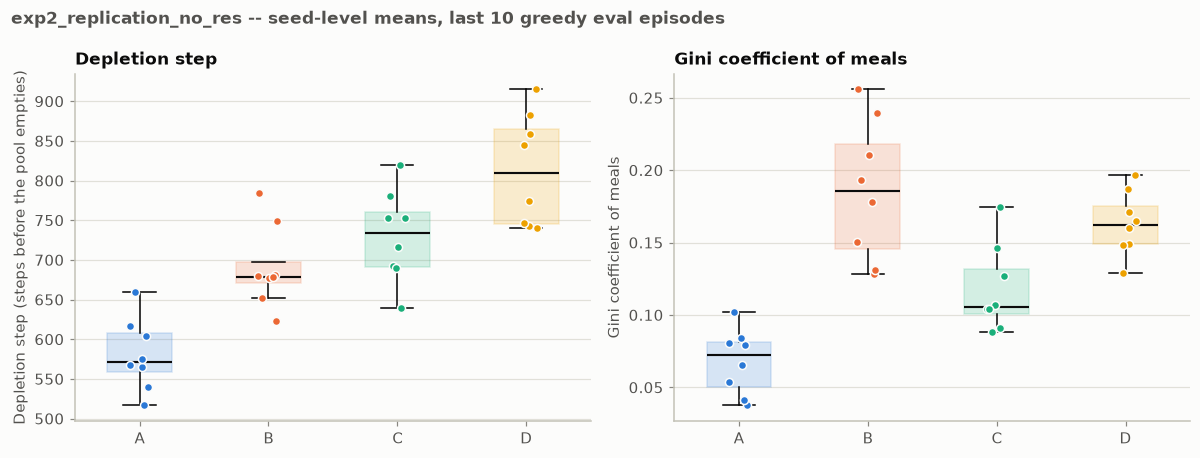

In [9]:
def box_strip(ax, data, metric, order):
    rng = np.random.default_rng(0)
    boxes = [data.loc[data["cell"] == c, metric].to_numpy() for c in order]
    bp = ax.boxplot(boxes, positions=range(len(order)), widths=0.5, showfliers=False,
                    patch_artist=True)
    for patch, color in zip(bp["boxes"], CAT):
        patch.set_facecolor(color); patch.set_alpha(0.18); patch.set_edgecolor(color)
    for med in bp["medians"]:
        med.set_color(INK["primary"]); med.set_linewidth(1.4)
    for i, (c, color) in enumerate(zip(order, CAT)):
        vals = data.loc[data["cell"] == c, metric].to_numpy()
        ax.scatter(i + rng.uniform(-0.08, 0.08, len(vals)), vals, s=28,
                   color=color, edgecolor=SURFACE, linewidth=1.0, zorder=3)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order)
    ax.set_ylabel(METRIC_LABEL[metric])


order = sorted(seed_df["cell"].unique())
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric in zip(axes, METRICS):
    box_strip(ax, seed_df, metric, order)
    ax.set_title(METRIC_LABEL[metric].split(" (")[0])
fig.suptitle(f"exp2_replication_no_res -- seed-level means, last {LAST_N_EVAL} greedy "
             f"eval episodes", x=0.012, ha="left", fontsize=11, fontweight="semibold",
             color=INK["secondary"])
fig.tight_layout()
plt.show()

## 8. Caveats

- **Seed count.** See §2's inventory — with fewer than `TARGET_SEEDS` (20)
  seeds per cell the ANOVA above is underpowered; read the effect sizes
  (partial η²), not only the p-values.
- **Censoring.** See §3 — if the censoring rate is non-negligible, the
  depletion-step comparison is conservative, since censored runs understate
  how long the empathic conditions would have lasted uncensored.
- **This is a replication check, not a new claim.** A null result here (cell
  means not separating as in the paper) would point at the training fix
  itself as the source of any discrepancy between the paper and `exp1`; a
  positive result here (paper's pattern reproduces) would mean `exp1`'s own
  differences from the paper are attributable to the resource-observation
  fix specifically.